# Проект: Разработка модели для предсказания возникновения инфаркта

<b>Цель исследования:</b> провести анализ данных для разработки модели, которая будет предсказывать возникновения инфаркта у пациента, для последующего развертывания через FastAPI

<b>Основные задачи исследования:</b> провести предобработку данных, исследовательский анализ данных, корреляционный анализ данных и обучить модель

<b>Исходные данные:</b> Нам дано два датафррейма с параметрами о пациентах - тренировочная и тестовая выборка, в тренировочной выборке 28 полей, а в тестовой 27, так как из нее вычеркнута целевая переменная.

## Загрузка данных

### Подгрузка требуемых инструментов

In [1]:
pip install optuna-integration[lightgbm] -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
!pip install phik -q

In [3]:
!pip install optuna -q

In [4]:
!pip install scikit-learn==1.1.3 -q

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
import optuna
import joblib

from scipy import stats

from sklearn.model_selection import train_test_split

from phik import phik_matrix
from phik.report import plot_correlation_matrix

from sklearn.metrics import roc_auc_score

from catboost import CatBoostClassifier

In [6]:
RANDOM_STATE = 42
TEST_SIZE = 0.25

### Написание класса для проведения исследовательского анализа данных

Напишем класс для предобработки данных и исследовательского анализа данных

In [7]:
class EDA:
    
    def __init__(self, filepath):
        self.filepath = filepath
        try:
            self.df = self.read_data()
            print('Данные загружены')
        except:
            self.df is None
            print('Все плохо')
    
    def read_data(self):
        if '.csv' in self.filepath:
            return pd.read_csv(self.filepath, encoding='utf-8')
        elif 'xlsx' in self.filepath:
            return pd.read_excel(self.filepath, encoding='utf-8')
        
    def intro(self):
        if self.df is None:
            print('Все плохо')
            return
        
        print('Первые пять строк и базовая инфа')
        display(self.df.head(5))
        display(self.df.describe())
        self.df.info()
        
    def feature_display(self, int_cols, dis_cols, cat_cols):
        if self.df is None:
            print('Все плохо')
            return
        
        print('Диаграммы размаха и гистограммы непрерывных признаков')
        for column in int_cols:
            plt.title(column)
            plt.boxplot(self.df[column])
            plt.show()
            
            plt.title(column)
            self.df[column].hist(bins=30,figsize=(5,4))
            plt.show()
        
        print('Столбчатые диаграммы дискретных признаков')        
        for column in dis_cols:
            plt.title(column)
            plt.bar(self.df[column].value_counts().index, self.df[column].value_counts().values)
            plt.show()
            
        print('Круговые диаграммы для категориальных признаков')
        for column in cat_cols:
            plt.pie(self.df[column].value_counts().values, labels=self.df[column].value_counts().index,autopct='%1.1f%%')
            plt.xlabel(column)
            plt.show()
        
    def phik_matrix(self,int_cols):
        phik_overview = self.df.drop('id',axis=1).phik_matrix(interval_cols=int_cols)
        plt.figure(figsize=(20, 12))
        sns.heatmap(phik_overview, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5, center=0)
        plt.title("Матрица корреляций")
        plt.show()

Подгрузим тренировочную выборку используя классовые методы и ознакомимся с базовой информацией о датафрейме

In [8]:
train = EDA('heart_train.csv')
df_train = train.df

Данные загружены


In [9]:
train.intro()

Первые пять строк и базовая инфа


,Unnamed: 0,Age,Cholesterol,Heart rate,Diabetes,Family History,Smoking,Obesity,Alcohol Consumption,Exercise Hours Per Week,...,Physical Activity Days Per Week,Sleep Hours Per Day,Heart Attack Risk (Binary),Blood sugar,CK-MB,Troponin,Gender,Systolic blood pressure,Diastolic blood pressure,id
0,0,0.359551,0.732143,0.074244,1.0,1.0,1.0,1.0,1.0,0.535505,...,3.0,0.333333,0.0,0.227018,0.048229,0.036512,Male,0.212903,0.709302,2664
1,1,0.202247,0.325000,0.047663,1.0,1.0,0.0,0.0,1.0,0.068690,...,3.0,0.833333,0.0,0.150198,0.017616,0.000194,Female,0.412903,0.569767,9287
2,2,0.606742,0.860714,0.055912,1.0,0.0,1.0,1.0,1.0,0.944001,...,2.0,1.000000,0.0,0.227018,0.048229,0.036512,Female,0.238710,0.220930,5379
3,3,0.730337,0.007143,0.053162,0.0,0.0,1.0,0.0,1.0,0.697023,...,0.0,0.333333,1.0,0.227018,0.048229,0.036512,Female,0.348387,0.267442,8222
4,4,0.775281,0.757143,0.021998,0.0,0.0,1.0,0.0,1.0,0.412878,...,5.0,1.000000,1.0,0.227018,0.048229,0.036512,Male,0.619355,0.441860,4047


,Unnamed: 0,Age,Cholesterol,Heart rate,Diabetes,Family History,Smoking,Obesity,Alcohol Consumption,Exercise Hours Per Week,...,Triglycerides,Physical Activity Days Per Week,Sleep Hours Per Day,Heart Attack Risk (Binary),Blood sugar,CK-MB,Troponin,Systolic blood pressure,Diastolic blood pressure,id
count,8685.000000,8685.000000,8685.000000,8685.000000,8442.000000,8442.000000,8442.000000,8442.000000,8442.000000,8685.000000,...,8685.000000,8442.000000,8685.000000,8685.000000,8685.000000,8685.000000,8685.000000,8685.000000,8685.000000,8685.000000
mean,4342.000000,0.449958,0.501070,0.050658,0.652097,0.489576,0.902867,0.498342,0.601990,0.503378,...,0.505484,3.508292,0.503737,0.346920,0.227339,0.048159,0.036689,0.450295,0.497634,4831.210823
std,2507.287877,0.231174,0.284716,0.023453,0.476333,0.499921,0.296157,0.500027,0.489517,0.284810,...,0.286320,2.281772,0.328061,0.476017,0.076635,0.075531,0.060157,0.170184,0.171830,2782.585625
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2171.000000,0.258427,0.267857,0.034830,0.000000,0.000000,1.000000,0.000000,0.000000,0.263286,...,0.263636,2.000000,0.166667,0.000000,0.227018,0.048229,0.036512,0.303226,0.348837,2425.000000
50%,4342.000000,0.460674,0.499780,0.050412,1.000000,0.000000,1.000000,0.000000,1.000000,0.502110,...,0.503603,3.000000,0.500000,0.000000,0.227018,0.048229,0.036512,0.445161,0.500000,4837.000000
75%,6513.000000,0.640449,0.746429,0.065995,1.000000,1.000000,1.000000,1.000000,1.000000,0.748709,...,0.750649,6.000000,0.833333,1.000000,0.227018,0.048229,0.036512,0.600000,0.651163,7242.000000
max,8684.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,7.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,9650.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8685 entries, 0 to 8684
Data columns (total 28 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Unnamed: 0                       8685 non-null   int64  
 1   Age                              8685 non-null   float64
 2   Cholesterol                      8685 non-null   float64
 3   Heart rate                       8685 non-null   float64
 4   Diabetes                         8442 non-null   float64
 5   Family History                   8442 non-null   float64
 6   Smoking                          8442 non-null   float64
 7   Obesity                          8442 non-null   float64
 8   Alcohol Consumption              8442 non-null   float64
 9   Exercise Hours Per Week          8685 non-null   float64
 10  Diet                             8685 non-null   int64  
 11  Previous Heart Problems          8442 non-null   float64
 12  Medication Use      

Сразу видно, что в датафрейме есть некоторое количество пропусков, также видно, какие то признаки являются категориальными, а какие то количественными, причем количественные также подразделяются на непрерывные и дискретные

Теперь подгрузим тренировочную выборку

In [10]:
test = EDA('heart_test.csv')
df_test = test.df

Данные загружены


In [11]:
test.intro()

Первые пять строк и базовая инфа


,Unnamed: 0,Age,Cholesterol,Heart rate,Diabetes,Family History,Smoking,Obesity,Alcohol Consumption,Exercise Hours Per Week,...,Triglycerides,Physical Activity Days Per Week,Sleep Hours Per Day,Blood sugar,CK-MB,Troponin,Gender,Systolic blood pressure,Diastolic blood pressure,id
0,0,0.494382,0.264286,0.062328,0.0,1.0,1.0,1.0,1.0,0.361618,...,0.306494,1.0,0.333333,0.227018,0.048229,0.036512,Male,0.283871,0.372093,7746
1,1,0.224719,0.953571,0.082493,1.0,0.0,0.0,1.0,0.0,0.996483,...,0.087013,0.0,0.166667,0.227018,0.048229,0.036512,Female,0.703226,0.441860,4202
2,2,0.629213,0.092857,0.064161,0.0,1.0,1.0,1.0,0.0,0.995561,...,0.205195,7.0,1.000000,0.102767,0.002666,0.088455,Male,0.458065,0.779070,6632
3,3,0.460674,0.567857,0.055912,1.0,1.0,1.0,1.0,1.0,0.437277,...,0.163636,0.0,0.666667,0.203557,0.056390,0.271774,Female,0.741935,0.255814,4639
4,4,0.719101,0.485714,0.022915,1.0,0.0,1.0,0.0,1.0,0.514920,...,0.580519,5.0,0.000000,0.227018,0.048229,0.036512,Male,0.412903,0.395349,4825


,Unnamed: 0,Age,Cholesterol,Heart rate,Diabetes,Family History,Smoking,Obesity,Alcohol Consumption,Exercise Hours Per Week,...,BMI,Triglycerides,Physical Activity Days Per Week,Sleep Hours Per Day,Blood sugar,CK-MB,Troponin,Systolic blood pressure,Diastolic blood pressure,id
count,966.00000,966.000000,966.000000,966.000000,935.000000,935.000000,935.000000,935.000000,935.000000,966.000000,...,966.000000,966.000000,935.000000,966.000000,966.000000,966.000000,966.000000,966.000000,966.000000,966.000000
mean,482.50000,0.452916,0.488181,0.051644,0.656684,0.481283,0.898396,0.516578,0.583957,0.490706,...,0.476796,0.486688,3.443850,0.512571,0.224127,0.048855,0.034926,0.447172,0.496822,4769.160455
std,279.00448,0.231068,0.282039,0.035502,0.475070,0.499917,0.302289,0.499993,0.493165,0.284902,...,0.291987,0.284534,2.302778,0.322292,0.065270,0.079742,0.053855,0.171837,0.173935,2818.815407
min,0.00000,0.044944,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000336,...,0.002598,0.000000,0.000000,0.000000,0.029644,0.000000,0.000194,0.012903,0.116279,0.000000
25%,241.25000,0.247191,0.243750,0.036664,0.000000,0.000000,1.000000,0.000000,0.000000,0.243431,...,0.217527,0.249675,1.000000,0.166667,0.227018,0.048229,0.036512,0.296774,0.348837,2275.750000
50%,482.50000,0.460674,0.499780,0.050412,1.000000,0.000000,1.000000,1.000000,1.000000,0.502110,...,0.471185,0.488961,3.000000,0.500000,0.227018,0.048229,0.036512,0.445161,0.488372,4769.500000
75%,723.75000,0.640449,0.710714,0.065995,1.000000,1.000000,1.000000,1.000000,1.000000,0.734425,...,0.720503,0.718182,5.000000,0.833333,0.227018,0.048229,0.036512,0.600000,0.639535,7206.000000
max,965.00000,0.853933,0.996429,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.998938,...,0.999496,0.998701,7.000000,1.000000,0.750988,1.000000,0.970871,0.741935,0.790698,9644.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 966 entries, 0 to 965
Data columns (total 27 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Unnamed: 0                       966 non-null    int64  
 1   Age                              966 non-null    float64
 2   Cholesterol                      966 non-null    float64
 3   Heart rate                       966 non-null    float64
 4   Diabetes                         935 non-null    float64
 5   Family History                   935 non-null    float64
 6   Smoking                          935 non-null    float64
 7   Obesity                          935 non-null    float64
 8   Alcohol Consumption              935 non-null    float64
 9   Exercise Hours Per Week          966 non-null    float64
 10  Diet                             966 non-null    int64  
 11  Previous Heart Problems          935 non-null    float64
 12  Medication Use        

Здесь все аналогично

## Предобработка данных

Избавимся от бесполезного поля с индексом

In [12]:
df_train = df_train.drop('Unnamed: 0',axis = 1)
df_test = df_test.drop('Unnamed: 0', axis = 1)

На этапе ознакомления с базовой информацией было выявлено, что имеется некоторое количество пропусков, также стоит заметить, что их количество ничтожно мало, поэтому "спасать" эти данные заполняя пропуски заглушкой не имеет большого смысла, так что в данном случае можно их просто вычеркнуть

In [13]:
df_train = df_train.dropna()
df_test = df_test.dropna()

Теперь давайте закодируем поле с полом пациента, чтобы можно было обучать модели(катбуст так то и без этого справится, но хгбуст и лгб не особо дружат с буквами)

In [14]:
df_train['Gender'] = df_train['Gender'].replace({'Male': 1, 'Female': 0})
df_test['Gender'] = df_test['Gender'].replace({'Male': 1, 'Female': 0})

In [15]:
train.df = df_train
test.df = df_test

## Исследовательский анализ данных

Создадим списки, которые будут классифицировать признаки по их природе, для дальнейшей визуализации с помощью классового метода

In [37]:
interval_cols = [
    "Age",
    "Cholesterol",
    "Heart rate",
    "Exercise Hours Per Week",
    "Sedentary Hours Per Day",
    "BMI",
    "Triglycerides",
    "Sleep Hours Per Day",
    "Blood sugar",
    "CK-MB",
    "Troponin",
    "Systolic blood pressure",
    "Diastolic blood pressure",
    "Income"
]

discrete_cols = [
    "Diet",
    "Stress Level",
    "Physical Activity Days Per Week"
]

cat_cols = [
    "Gender",
    "Diabetes",
    "Family History",
    "Smoking",
    "Obesity",
    "Alcohol Consumption",
    "Previous Heart Problems",
    "Medication Use"
]

Теперь используя классовые методы мы нарисуем диаграммы размаха и гистограммы для непрерывных признаков, столбчатые диаграммы для дискретных и круговые для категориальных, вначале для тренировочной выборки, а потом и для тестовой

Диаграммы размаха и гистограммы непрерывных признаков


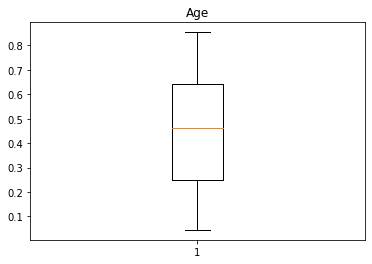

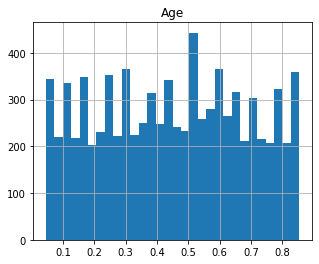

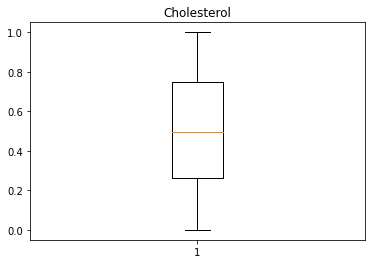

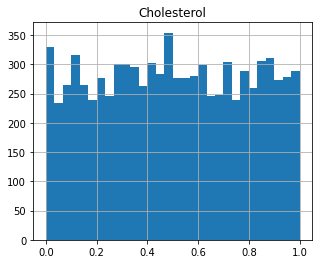

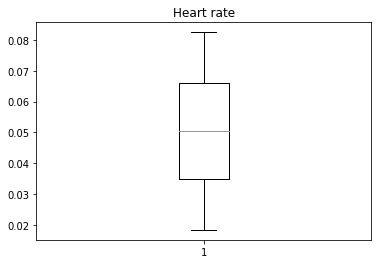

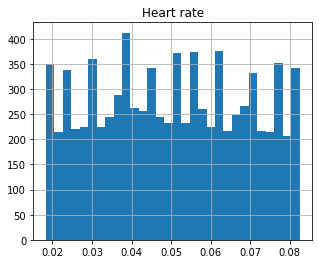

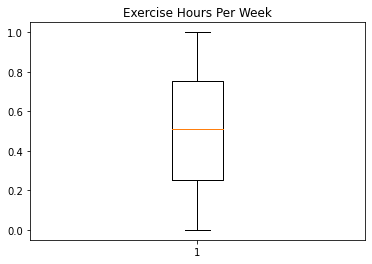

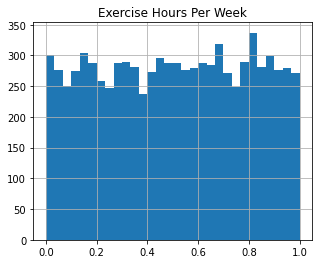

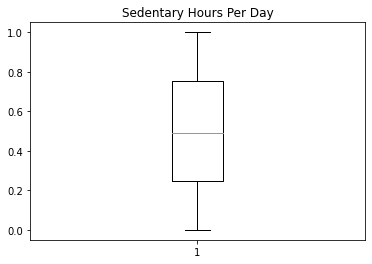

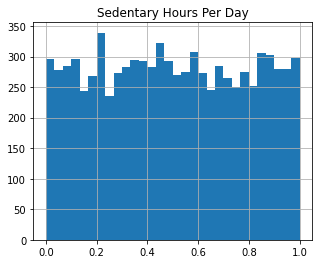

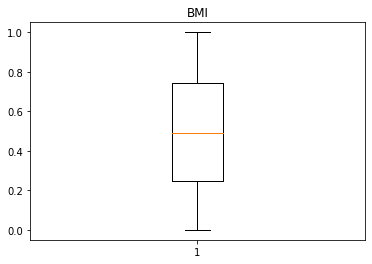

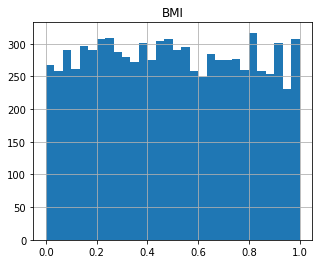

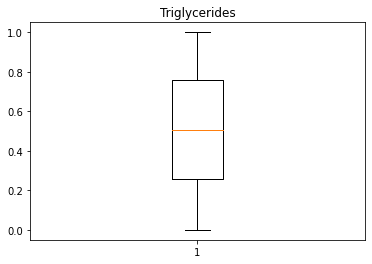

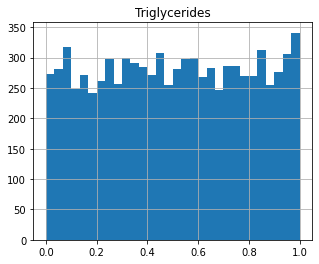

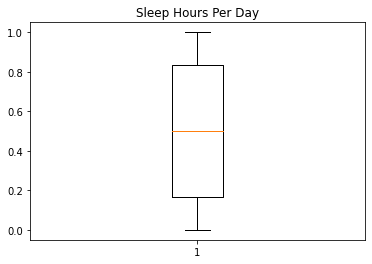

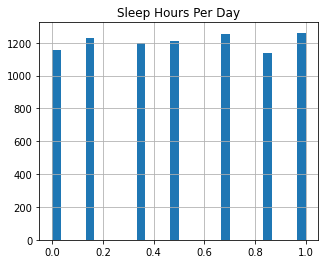

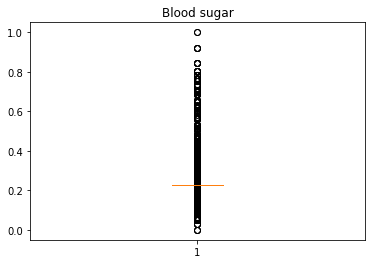

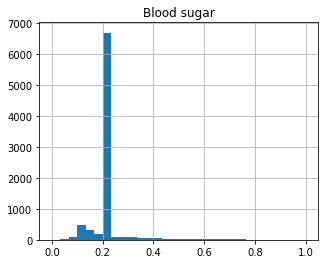

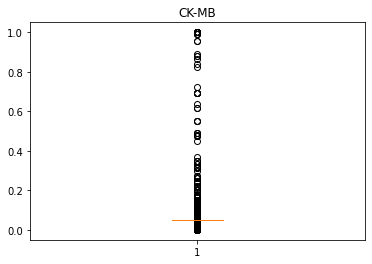

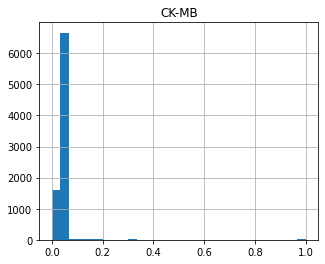

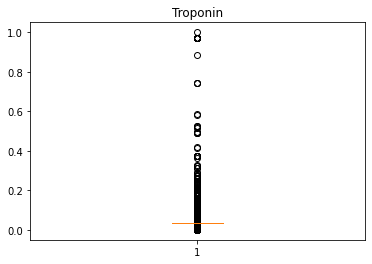

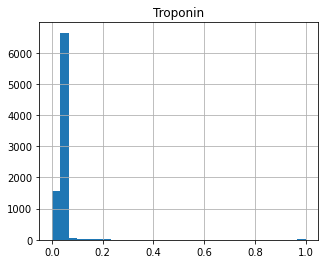

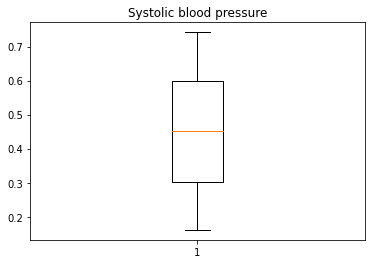

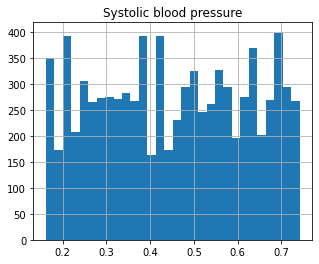

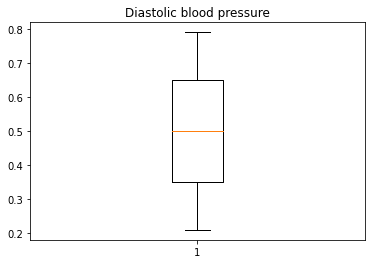

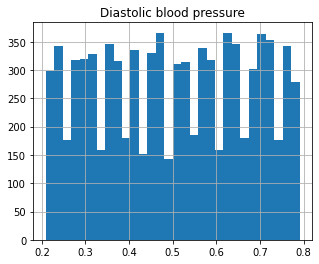

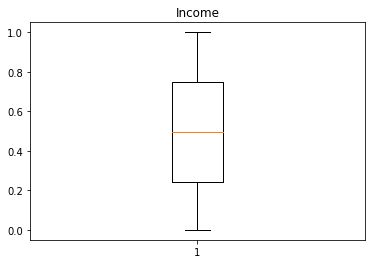

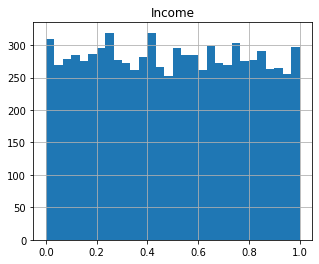

Столбчатые диаграммы дискретных признаков


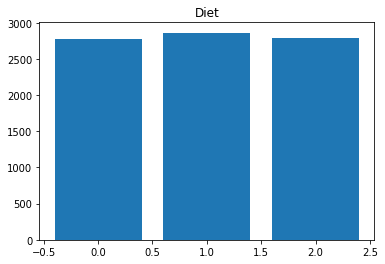

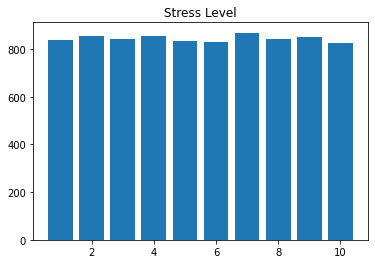

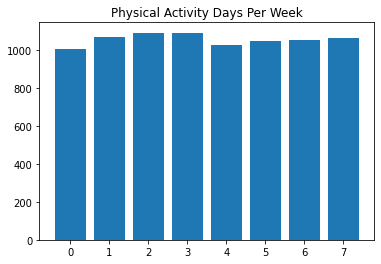

Круговые диаграммы для категориальных признаков


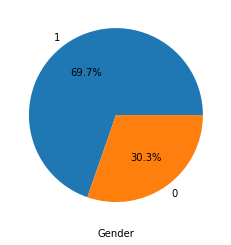

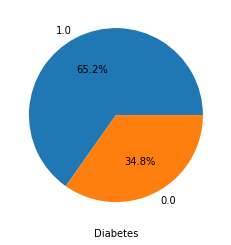

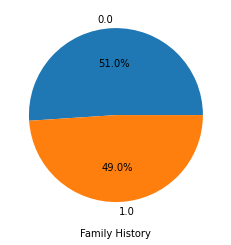

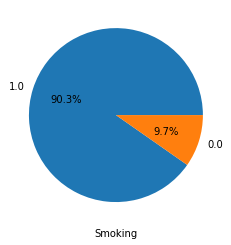

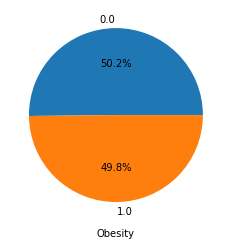

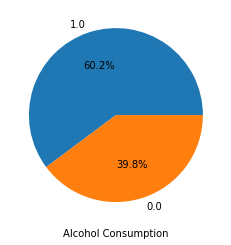

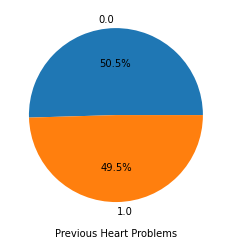

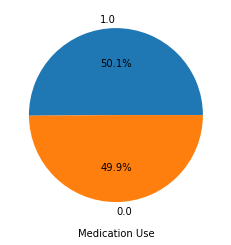

In [19]:
train.feature_display(interval_cols,discrete_cols,cat_cols)

Диаграммы размаха и гистограммы непрерывных признаков


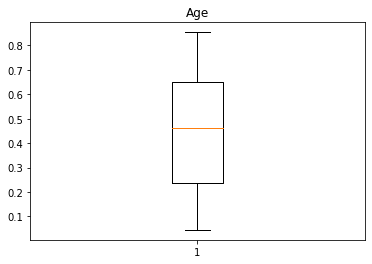

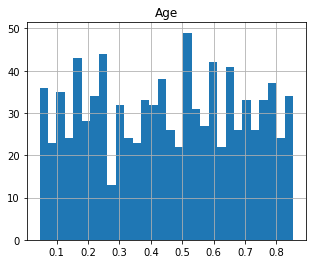

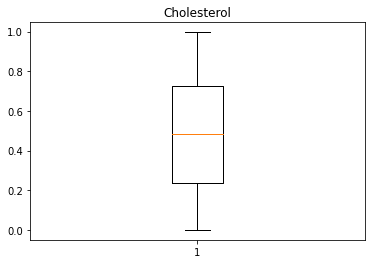

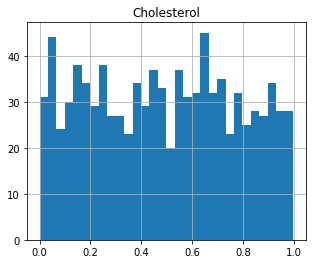

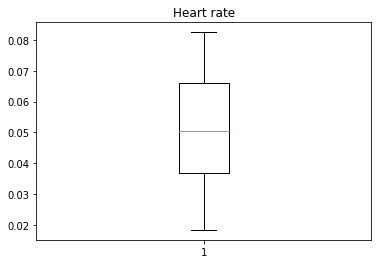

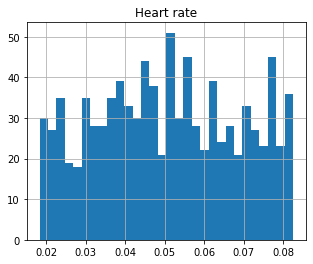

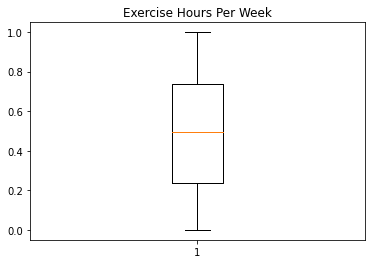

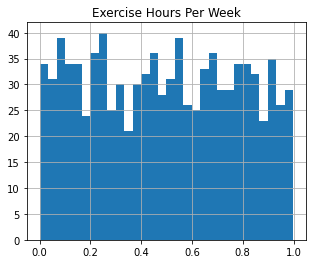

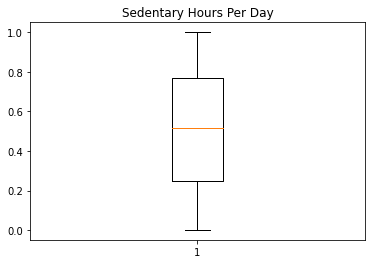

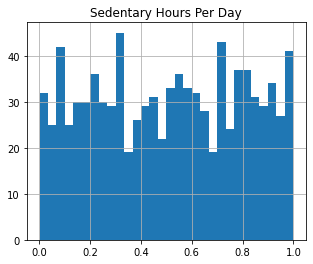

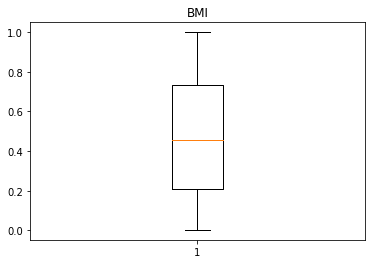

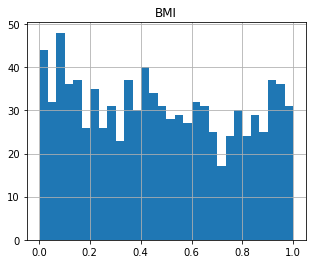

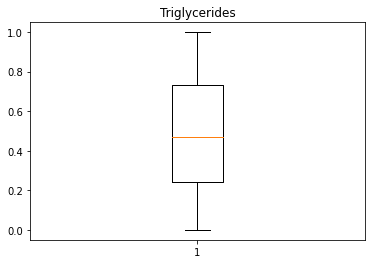

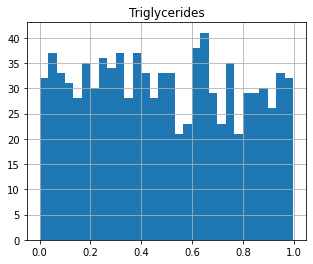

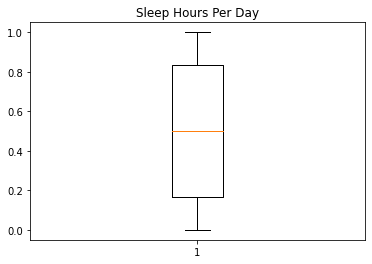

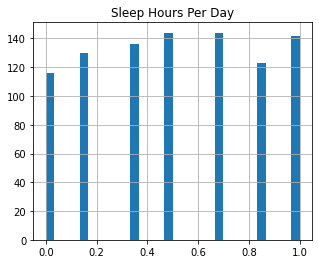

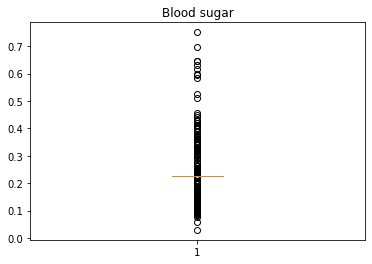

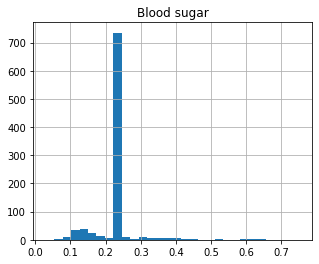

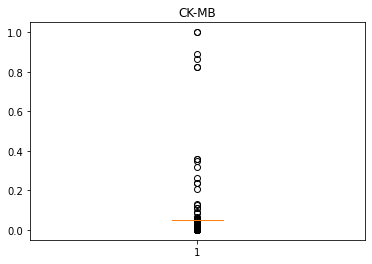

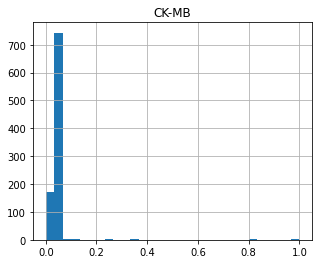

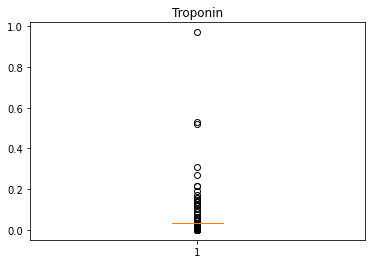

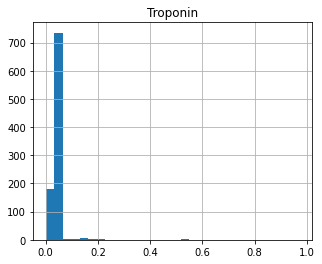

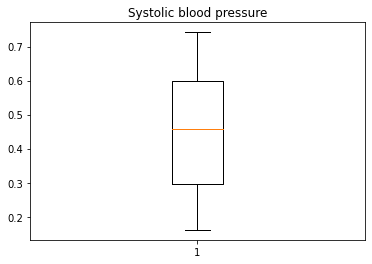

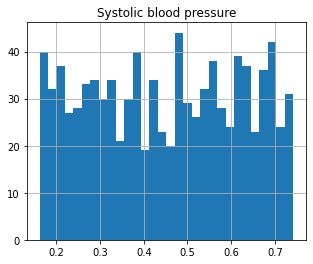

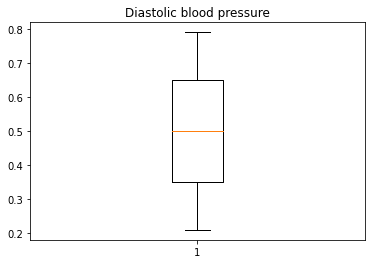

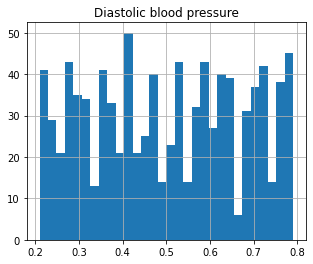

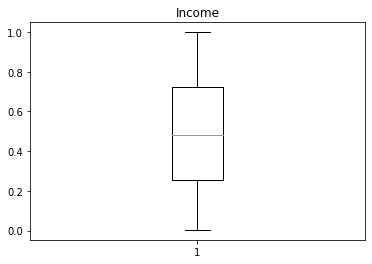

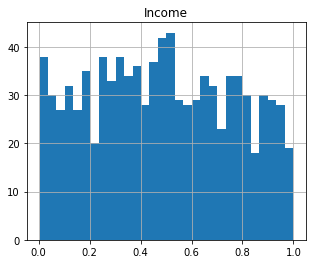

Столбчатые диаграммы дискретных признаков


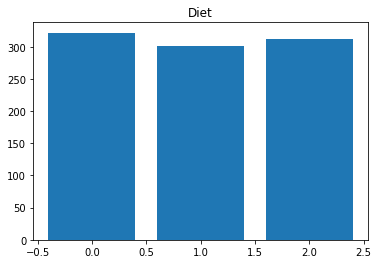

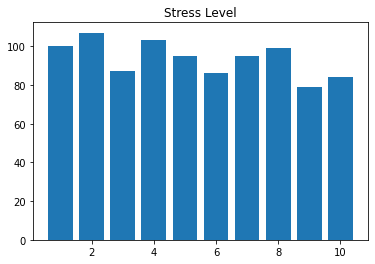

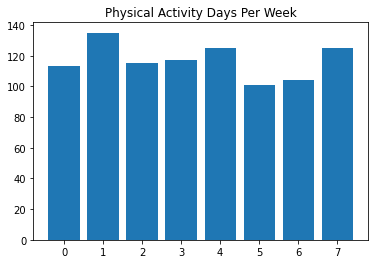

Круговые диаграммы для категориальных признаков


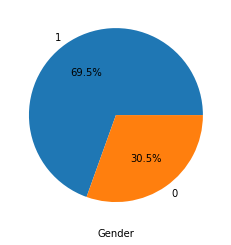

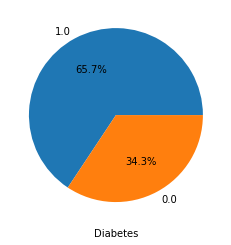

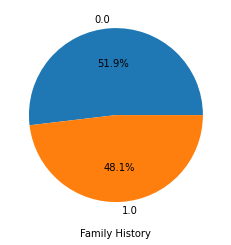

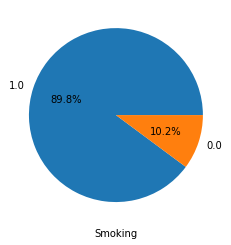

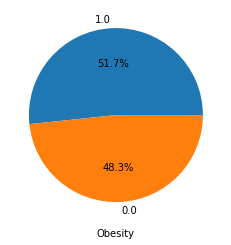

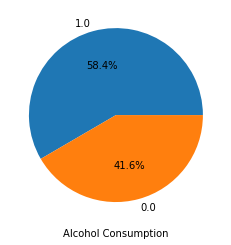

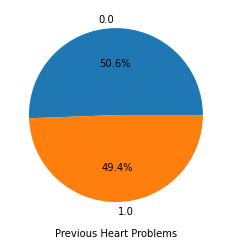

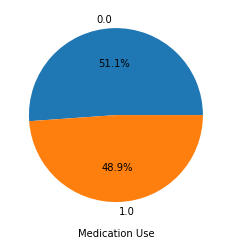

In [20]:
test.feature_display(interval_cols,discrete_cols,cat_cols)

По итогу исследовательского анализа данных можно сказать, что большинство количественных признаков имеют равномерное распределение, что не похоже на "реальные" данные

## Корреляционный анализ данных

Нарисуем матрицы корреляций для всех наших выборок

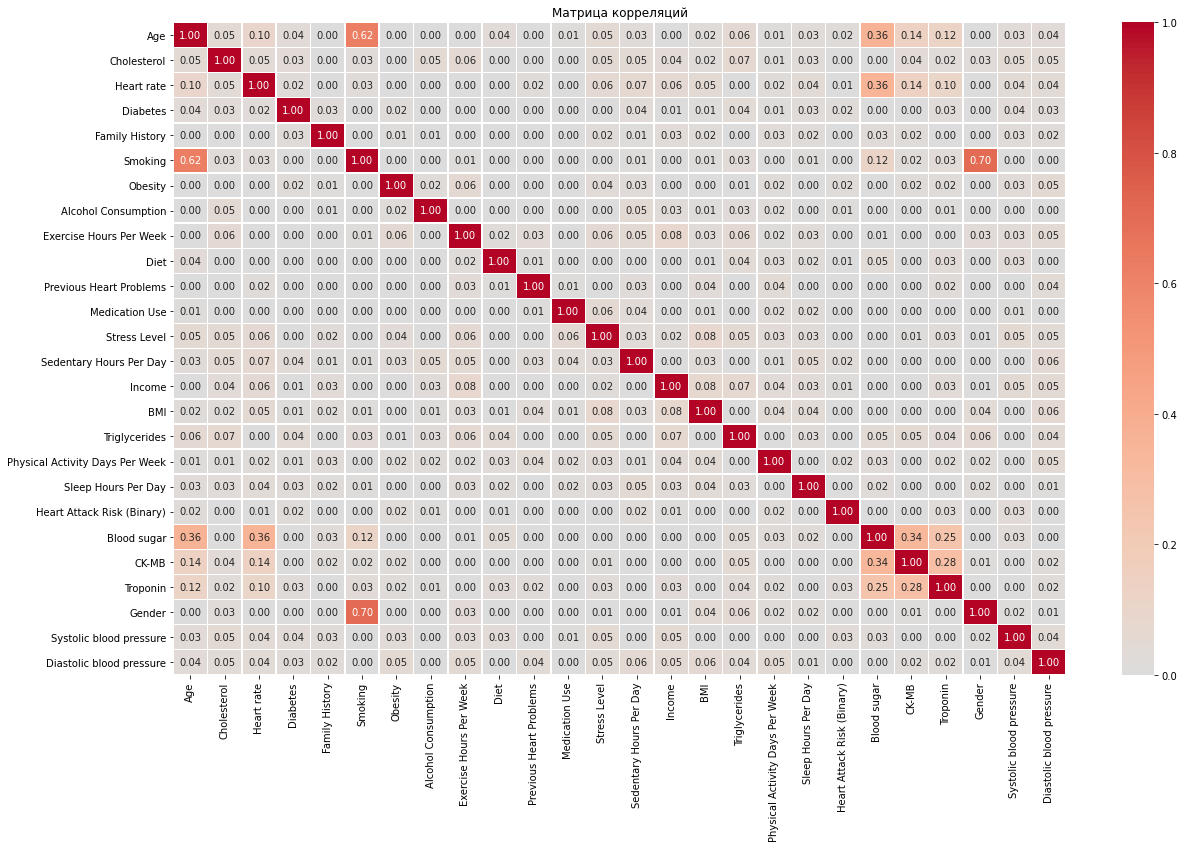

In [21]:
train.phik_matrix(interval_cols)

На основе матрицы можно уверено сказать, что целевая переменная почти не коррелирует с другими признаками в наших данных, у большинства признаков коэфициент корреляции вообще равен нулю, это не значит, что они бесполезные и их надо вычеркнуть, но и хорошего в данной ситуации мало

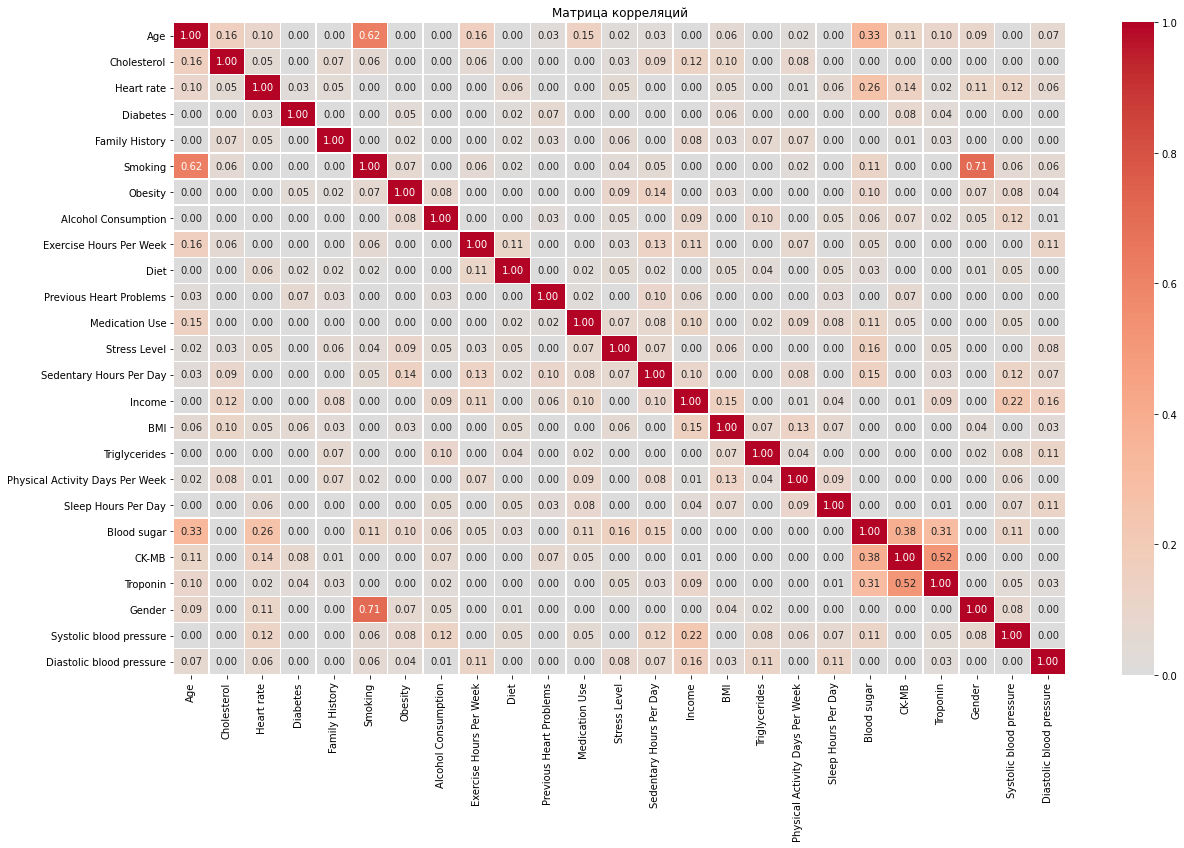

In [22]:
test.phik_matrix(interval_cols)

С тестовой выборкой все так же грустно

## Обучение моделей

Приступим к основному этапу исследования, для начала надо бы вычеркнуть бесполезный для обучения признак с доходом пациента и разделим наши данные на тренировочную и валидационную выборку

In [16]:
df_train = df_train.drop('Income',axis=1)
df_test = df_test.drop('Income',axis=1)

In [17]:
X = df_train.drop(['Heart Attack Risk (Binary)','id'], axis=1)
y = df_train['Heart Attack Risk (Binary)']

X_train, X_val, y_train, y_val = train_test_split(X,
                                                  y,
                                                  random_state = RANDOM_STATE,
                                                  test_size = TEST_SIZE,
                                                  stratify=df_train['Heart Attack Risk (Binary)'])

Теперь начнем подбор гиперпараметров для catboost, XGBoost, LGBM моделей

In [22]:
def objective_lgbm(trial):
    params = {'objective': 'binary',
            'metric': ['binary_logloss', 'auc'], 
            'verbosity': -1,
            'boosting_type': 'gbdt',
            'n_estimators': trial.suggest_int('n_estimators', 100, 2000, step=100),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
            'num_leaves': trial.suggest_int('num_leaves', 20, 300),
            'max_depth': trial.suggest_int('max_depth', 3, 12),
            'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'random_state': RANDOM_STATE}
    
    model = lgb.LGBMClassifier(**params)
    metric = optuna.integration.LightGBMPruningCallback(trial, 'auc')
    _break = lgb.early_stopping(50, verbose=False)
    
    model.fit(X_train, y_train,
              eval_set=[(X_val, y_val)],
              callbacks=[metric, _break])
              
    preds = model.predict_proba(X_val)[:, 1]
    roc_auc = roc_auc_score(y_val, preds)
    
    return roc_auc

In [23]:
study_lgbm = optuna.create_study(
    pruner=optuna.pruners.MedianPruner(n_warmup_steps=20),
    direction='maximize')

study_lgbm.optimize(objective_lgbm, n_trials=200)

print("Лучшая модель:", study_lgbm.best_params)
print()
print("Лучшее значение ROC AUC:", study_lgbm.best_value)

[I 2025-09-18 17:07:18,284] A new study created in memory with name: no-name-b834dbff-af66-4c32-878c-2e32fd9517b2
[I 2025-09-18 17:08:43,061] Trial 0 finished with value: 0.5304955924950175 and parameters: {'n_estimators': 700, 'learning_rate': 0.1499202089212858, 'num_leaves': 25, 'max_depth': 12, 'min_child_samples': 63, 'subsample': 0.823727202010212, 'colsample_bytree': 0.6581983105112784}. Best is trial 0 with value: 0.5304955924950175.
[I 2025-09-18 17:09:27,065] Trial 1 finished with value: 0.5344713438831811 and parameters: {'n_estimators': 1200, 'learning_rate': 0.21935348122435308, 'num_leaves': 270, 'max_depth': 4, 'min_child_samples': 33, 'subsample': 0.8200906319595702, 'colsample_bytree': 0.6186299965094119}. Best is trial 1 with value: 0.5344713438831811.
[I 2025-09-18 17:10:11,165] Trial 2 finished with value: 0.5570085881315191 and parameters: {'n_estimators': 300, 'learning_rate': 0.2766599761644024, 'num_leaves': 118, 'max_depth': 3, 'min_child_samples': 16, 'subsamp

Лучшая модель: {'n_estimators': 1800, 'learning_rate': 0.09799790695289326, 'num_leaves': 234, 'max_depth': 12, 'min_child_samples': 8, 'subsample': 0.8112799602450887, 'colsample_bytree': 0.6616009674062439}

Лучшее значение ROC AUC: 0.5879466913885939


Очень плохая метрика

In [24]:
def objective_catboost(trial):
    params = {'iterations': trial.suggest_int('iterations', 500, 2000),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
            'depth': trial.suggest_int('depth', 4, 10),
            'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1e-3, 10.0, log=True),
            'border_count': trial.suggest_int('border_count', 32, 255),
            'random_strength': trial.suggest_float('random_strength', 1, 20),
            'objective': 'Logloss',
            'eval_metric': 'AUC',
            'random_seed': RANDOM_STATE,
            'verbose': 0}
    
    model = CatBoostClassifier(**params)
    metric = optuna.integration.CatBoostPruningCallback(trial, 'AUC')
    model.fit(X_train, y_train,
              eval_set=[(X_val, y_val)],
              early_stopping_rounds=50,
              callbacks=[metric],
              verbose=0)
    
    preds = model.predict_proba(X_val)[:, 1]
    roc_auc = roc_auc_score(y_val, preds)
    
    return roc_auc

In [25]:
study_catboost = optuna.create_study(
    pruner=optuna.pruners.MedianPruner(n_warmup_steps=5),
    direction='maximize'
)
study_catboost.optimize(objective_catboost, n_trials=50)

print("Лучшая модель", study_catboost.best_params)
print()
print("Лучшее значение ROC AUC:", study_catboost.best_value)

[I 2025-09-18 22:01:30,834] A new study created in memory with name: no-name-4eab8d81-1558-4831-b92a-f47fb1092da0
/tmp/ipykernel_205/3997194888.py:16: ExperimentalWarning: CatBoostPruningCallback is experimental (supported from v3.0.0). The interface can change in the future.
  metric = optuna.integration.CatBoostPruningCallback(trial, 'AUC')
[I 2025-09-18 22:01:40,245] Trial 0 finished with value: 0.5850393223375521 and parameters: {'iterations': 1638, 'learning_rate': 0.05372764735170783, 'depth': 9, 'l2_leaf_reg': 0.02438943742757261, 'border_count': 246, 'random_strength': 4.7139097296042785}. Best is trial 0 with value: 0.5850393223375521.
/tmp/ipykernel_205/3997194888.py:16: ExperimentalWarning: CatBoostPruningCallback is experimental (supported from v3.0.0). The interface can change in the future.
  metric = optuna.integration.CatBoostPruningCallback(trial, 'AUC')
[I 2025-09-18 22:01:42,012] Trial 1 finished with value: 0.560201022126516 and parameters: {'iterations': 641, 'lear

Лучшая модель {'iterations': 1335, 'learning_rate': 0.1730309660424917, 'depth': 10, 'l2_leaf_reg': 0.004605934134502474, 'border_count': 116, 'random_strength': 11.446960989813128}

Лучшее значение ROC AUC: 0.5918466536407145


Чуть лучше, все еще ужасно, но имеем, что имеем

Теперь выгрузим нашу финальную модель и обработанную тестовую выборку

In [23]:
model = CatBoostClassifier(iterations=1335,
                           learning_rate=0.1730309660424917,
                           depth = 10,
                           l2_leaf_reg = 0.004605934134502474,
                           border_count = 116,
                           random_strength = 11.446960989813128,
                           random_state = RANDOM_STATE)
model.fit(X,y)

filename = 'final_model.joblib'
joblib.dump(model, filename, protocol=4)

0:	learn: 0.6603777	total: 21.2ms	remaining: 28.3s
1:	learn: 0.6307506	total: 42.3ms	remaining: 28.2s
2:	learn: 0.6129346	total: 63.4ms	remaining: 28.1s
3:	learn: 0.6049711	total: 84.8ms	remaining: 28.2s
4:	learn: 0.5887569	total: 105ms	remaining: 28s
5:	learn: 0.5851714	total: 113ms	remaining: 24.9s
6:	learn: 0.5712372	total: 134ms	remaining: 25.3s
7:	learn: 0.5590372	total: 155ms	remaining: 25.8s
8:	learn: 0.5561047	total: 163ms	remaining: 24s
9:	learn: 0.5484089	total: 186ms	remaining: 24.6s
10:	learn: 0.5440179	total: 208ms	remaining: 25s
11:	learn: 0.5341097	total: 230ms	remaining: 25.3s
12:	learn: 0.5339960	total: 232ms	remaining: 23.6s
13:	learn: 0.5221729	total: 253ms	remaining: 23.9s
14:	learn: 0.5070127	total: 275ms	remaining: 24.2s
15:	learn: 0.4999608	total: 296ms	remaining: 24.4s
16:	learn: 0.4954978	total: 322ms	remaining: 24.9s
17:	learn: 0.4815998	total: 343ms	remaining: 25.1s
18:	learn: 0.4768788	total: 365ms	remaining: 25.3s
19:	learn: 0.4738478	total: 386ms	remaining

['final_model.joblib']

In [22]:
df_test.to_csv('final_test.csv',index=False)

## Итоговый вывод

Вначале были подгружены данные с помощью написанного класса и методов для него.

На этапе предобработки данных были убраны все пропуски, так как их количество не велико и был вычеркнуто поле с индексом

На этапе исследовательского анализа данных не было обнаружено выбросов, но в остальном хорошего мало, так как подавляющее большинство количественных признаков имеет равномерное распределение, что крайне не относится с положением вещей в реальности

На этапе корреляционного анализа данных мы увидели, что целевая переменная почти не коррелирует с остальными признаками, что дает препосылки к плохому обучению моделей

На этапе обучения модели мы подобрали оптимальные гиперпараметры для трех ансамблевых моделей, но даже оптимальные параметры не могут дать адекватное значение метрики, максимальное, что мы смогли выжать из данных это значение roc_auc равное 0.5918466536407145. Абсолютно неудовлетворительное значение из которого мы можем сделать вывод, что данные имеют синтетическую природу, и в данной ситуации извлечь из них что то большее невозможно

<img src="i.png" alt="Описание изображения" width="500"/>